In [ ]:
# ! pip install CodonTransformer  
from CodonTransformer.CodonEvaluation import get_min_max_percentage


In [ ]:

# same table as cc
cf = {}
for line in open("../examples/codon_table_minmax_hsapiens"):
    f = line.split()
    if len(f) < 10 or f[8] == "End":        # sense codons only
        continue
    cf.setdefault(f[8], ([], []))
    cf[f[8]][0].append(f[9].upper())
    cf[f[8]][1].append(float(f[3]))

dna = "".join(l.strip() for l in open("../examples/example.fasta") if not l.startswith(">")).upper().replace("U", "T")
cod = [dna[i:i+3] for i in range(0, len(dna) - len(dna) % 3, 3)]
dna = "".join(c for c in cod if c not in ("TAA", "TAG", "TGA"))   # drop stops


In [4]:
mm = [v for v in get_min_max_percentage(dna, cf, window_size=18) if v is not None]
print(len(mm), [round(v, 2) for v in mm[:10]])

130 [71.91, 74.29, 72.13, 76.9, 70.59, 66.8, 58.14, 50.03, 41.98, 42.64]


In [ ]:
!./coconut -minmax ../examples/codon_table_minmax_hsapiens ../examples/example.fasta

Codon usage data loaded successfully.
ID,residue,codon,aminoacid,usage,max,min,ave,minmax
ENST00000335295.4 HBB,1,ATG,M,24.67,26.86,12.79,19.07,71.91
ENST00000335295.4 HBB,2,GTG,V,25.01,27.19,11.96,18.69,74.29
ENST00000335295.4 HBB,3,CAT,H,24.51,26.69,12.51,18.85,72.13
ENST00000335295.4 HBB,4,CTG,L,25.47,27.42,12.30,18.97,76.90
ENST00000335295.4 HBB,5,ACT,T,24.47,26.61,13.11,19.35,70.59
ENST00000335295.4 HBB,6,CCT,P,25.35,27.76,14.39,20.51,66.80
ENST00000335295.4 HBB,7,GAG,E,24.99,28.22,14.39,20.51,58.14
ENST00000335295.4 HBB,8,GAG,E,23.39,27.26,13.38,19.52,50.04
ENST00000335295.4 HBB,9,AAG,K,21.79,26.29,12.37,18.53,41.98


In [ ]:
! head -n 130 ../examples/example_minmax.csv
mm

ID,residue,codon,aminoacid,usage,max,min,ave,minmax
ENST00000335295.4 HBB,1,ATG,M,24.67,26.86,12.79,19.07,71.91
ENST00000335295.4 HBB,2,GTG,V,25.01,27.19,11.96,18.69,74.29
ENST00000335295.4 HBB,3,CAT,H,24.51,26.69,12.51,18.85,72.13
ENST00000335295.4 HBB,4,CTG,L,25.47,27.42,12.30,18.97,76.90
ENST00000335295.4 HBB,5,ACT,T,24.47,26.61,13.11,19.35,70.59
ENST00000335295.4 HBB,6,CCT,P,25.35,27.76,14.39,20.51,66.80
ENST00000335295.4 HBB,7,GAG,E,24.99,28.22,14.39,20.51,58.14
ENST00000335295.4 HBB,8,GAG,E,23.39,27.26,13.38,19.52,50.04
ENST00000335295.4 HBB,9,AAG,K,21.79,26.29,12.37,18.53,41.98
ENST00000335295.4 HBB,10,TCT,S,22.22,26.72,12.62,18.87,42.64
ENST00000335295.4 HBB,11,GCC,A,22.91,27.18,12.79,19.08,47.30
ENST00000335295.4 HBB,12,GTT,V,23.57,27.84,12.77,19.05,51.48
ENST00000335295.4 HBB,13,ACT,T,24.20,27.52,12.98,19.12,60.47
ENST00000335295.4 HBB,14,GCC,A,24.13,27.14,12.89,18.90,63.45
ENST00000335295.4 HBB,15,CTG,L,24.79,27.80,12.88,18.87,66.31
ENST00000335295.4 HBB,16,TGG,W,24.79,27.80

[71.91325347069389,
 74.2893079021447,
 72.12613484764407,
 76.89537019270306,
 70.59344778564729,
 66.8038128338145,
 58.13853021648339,
 50.03379651507085,
 41.97865108235429,
 42.637487029525424,
 47.29495687363884,
 51.47458162298697,
 60.46842436071314,
 63.45201629900231,
 66.30568825973866,
 66.30568825973866,
 68.81614723949914,
 62.50984220244313,
 62.05911545827756,
 58.85687455063899,
 58.59686080335479,
 56.71793077544469,
 61.0034307404073,
 66.58250364404475,
 74.99708182560984,
 80.01626557647278,
 87.49397906905459,
 86.38088177576196,
 83.64164093413433,
 76.87903873234798,
 73.39987896672946,
 77.31435275165897,
 72.83225887669032,
 63.164043285784544,
 57.80015336911944,
 64.08806036062272,
 57.82259442830278,
 47.18150361748975,
 47.18150361748984,
 47.25367930010837,
 41.84129403207367,
 40.812665266594585,
 42.201446375343515,
 50.60662448827692,
 49.88823778167107,
 45.29577014931881,
 44.34020090718322,
 49.3160069517058,
 53.02236928810821,
 36.29425069250904,


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

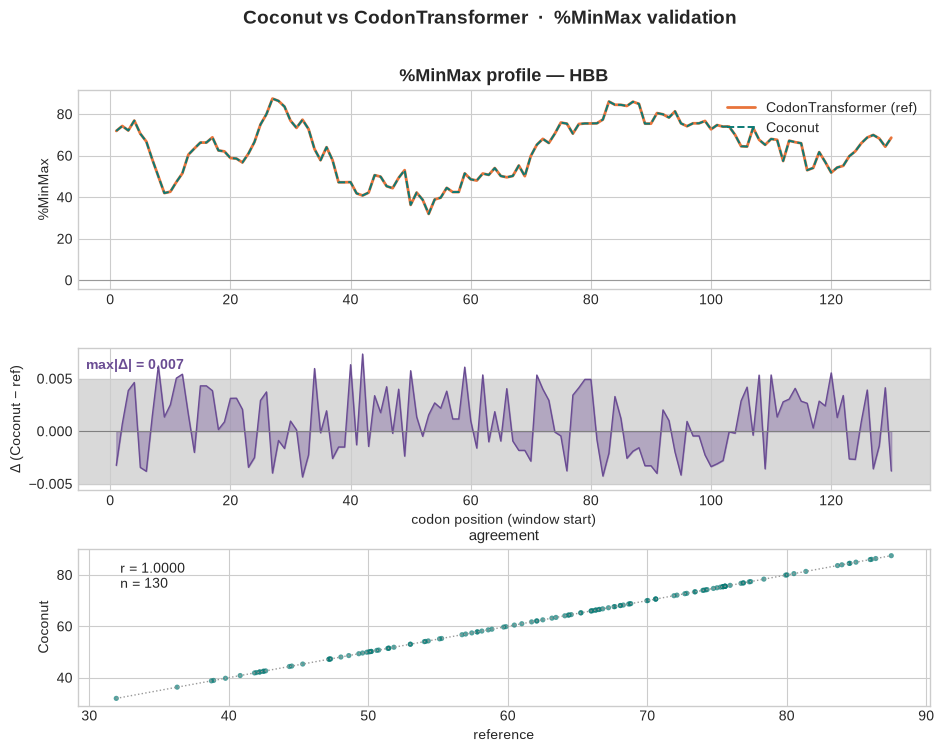

In [ ]:


# ref = CodonTransformer, coc = Coconut. Trim to common length (drops Coconut's extra stop window).
ref = np.array(mm, dtype=float)

coconut_mm = [float(l.split(",")[-1]) for l in open("../examples/example_minmax.csv").read().splitlines()[1:]]
coc = np.array(coconut_mm, dtype=float)

n = min(len(ref), len(coc)); ref, coc = ref[:n], coc[:n]
delta = coc - ref
pos = np.arange(1, n + 1)
r = np.corrcoef(ref, coc)[0, 1]
maxd = np.abs(delta).max()

plt.style.use("seaborn-v0_8-whitegrid")
C_COC, C_REF, C_D = "#0B7A75", "#E8743B", "#6A4C93"
fig = plt.figure(figsize=(11, 8))
gs = GridSpec(3, 1, height_ratios=[1.4, 1, 1.1], hspace=0.35, wspace=0.28, figure=fig)

# 1) overlaid profiles
ax1 = fig.add_subplot(gs[0, :])
ax1.plot(pos, ref, color=C_REF, lw=2, label="CodonTransformer (ref)")
ax1.plot(pos, coc, color=C_COC, lw=1.4, ls="--", label="Coconut")
ax1.axhline(0, color="0.6", lw=0.8)
ax1.set_ylabel("%MinMax"); ax1.set_title("%MinMax profile — HBB", fontsize=13, weight="bold")
ax1.legend(frameon=False, loc="upper right")

# 2) delta per position
ax2 = fig.add_subplot(gs[1, :], sharex=ax1)
ax2.axhspan(-0.005, 0.005, color="0.85", zorder=0)          # 2-decimal rounding band
ax2.fill_between(pos, delta, color=C_D, alpha=0.35)
ax2.plot(pos, delta, color=C_D, lw=1)
ax2.axhline(0, color="0.5", lw=0.8)
ax2.set_ylabel("Δ (Coconut − ref)"); ax2.set_xlabel("codon position (window start)")
ax2.annotate(f"max|Δ| = {maxd:.3f}", xy=(0.01, 0.85), xycoords="axes fraction",
             fontsize=10, color=C_D, weight="bold")

# 3) agreement scatter
ax3 = fig.add_subplot(gs[2, 0])
lo, hi = min(ref.min(), coc.min()), max(ref.max(), coc.max())
ax3.plot([lo, hi], [lo, hi], color="0.6", lw=1, ls=":")
ax3.scatter(ref, coc, s=14, color=C_COC, alpha=0.7, edgecolor="none")
ax3.set_xlabel("reference"); ax3.set_ylabel("Coconut"); ax3.set_title("agreement", fontsize=11)
ax3.annotate(f"r = {r:.4f}\nn = {n}", xy=(0.05, 0.75), xycoords="axes fraction", fontsize=10)

fig.suptitle("Coconut vs CodonTransformer  ·  %MinMax validation", fontsize=14, weight="bold", y=0.98)
plt.show()